<img src=../figures/Brown_logo.svg width=50%>

## Data-Driven Design & Analyses of Structures & Materials (3dasm)

## Lecture 3

### Miguel A. Bessa | <a href = "mailto: miguel_bessa@brown.edu">miguel_bessa@brown.edu</a>  | Associate Professor

**What:** A lecture of the "3dasm" course

**Where:** This notebook comes from this [repository](https://github.com/bessagroup/3dasm_course)

**Reference for entire course:** Murphy, Kevin P. *Probabilistic machine learning: an introduction*. MIT press, 2022. Available online [here](https://probml.github.io/pml-book/book1.html)

**How:** We try to follow Murphy's book closely, but the sequence of Chapters and Sections is different. The intention is to use notebooks as an introduction to the topic and Murphy's book as a resource.
* If working offline: Go through this notebook and read the book.
* If attending class in person: listen to me (!) but also go through the notebook in your laptop at the same time. Read the book.
* If attending lectures remotely: listen to me (!) via Zoom and (ideally) use two screens where you have the notebook open in 1 screen and you see the lectures on the other. Read the book.

**Optional reference (the "bible" by the "bishop"... pun intended 😆) :** Bishop, Christopher M. *Pattern recognition and machine learning*. Springer Verlag, 2006.

**References/resources to create this notebook:**
* [Car figure](https://korkortonline.se/en/theory/reaction-braking-stopping/)

Apologies in advance if I missed some reference used in this notebook. Please contact me if that is the case, and I will gladly include it here.

## **OPTION 1**. Run this notebook **locally in your computer**:
1. Confirm that you have the '3dasm' mamba (or conda) environment (see Lecture 1).
2. Go to the 3dasm_course folder in your computer and pull the last updates of the [repository](https://github.com/bessagroup/3dasm_course):
```
git pull
```
    - Note: if you can't pull the repo due to conflicts (and you can't handle these conflicts), use this command (with **caution**!) and your repo becomes the same as the one online:
```
git reset --hard origin/main
```
3. Open command window and load JupyterLab (it will open in your internet browser):
```
jupyter lab
```
5. Open notebook of this Lecture and choose the '3dasm' kernel.

## **OPTION 2**. Use **Google's Colab** (no installation required, but times out if idle):

1. go to https://colab.research.google.com
2. login
3. File > Open notebook
4. click on Github (no need to login or authorize anything)
5. paste the git link: https://github.com/bessagroup/3dasm_course
6. click search and then click on the notebook for this Lecture.

In [1]:
# Basic plotting tools needed in Python.

import matplotlib.pyplot as plt # import plotting tools to create figures
import numpy as np # import numpy to handle a lot of things!
from IPython.display import display, Math # to print with Latex math

%config InlineBackend.figure_format = "retina" # render higher resolution images in the notebook
plt.rcParams["figure.figsize"] = (8,4) # rescale figure size appropriately for slides

## Outline for today

* Moments of a distribution (from last class)
    - Expected value, variance, standard deviation
    - Mode, and mean vs mode
* Probability: multivariate models
    - Introduction to joint pdfs
    - Marginal pdfs
    - Conditional pdfs

**Reading material**: This notebook + Chapter 2 (Section 2.2) and Chapter 3 (until Section 3.3)

## Car stopping distance problem

<img src="../figures/reaction-braking-stopping.svg" title="Car stopping distance" width="25%" align="right">

$y = {\color{blue}z} x + 0.1 x^2$

where $z$ is a continuous <a title="random variable">rv</a> such that $z \sim \mathcal{N}(\mu_z=1.5,\sigma_z^2=0.5^2)$.

* What is the **expected** value for the reaction time $z$?

This is not a trick question! It's the mean $\mu_z$, of course!

* But how do we compute the expected value for any distribution?

## Moments of a distribution

### First moment: Expected value or mean

The expected value (mean) of a distribution is the **first moment** of the distribution:

$$
\mathbb{E}[z]= \int_{\mathcal{Z}}z p(z) dz
$$

where $\mathcal{Z}$ indicates the support of the distribution (the $z$ domain). 

* Often, $\mathcal{Z}$ is omitted as it is usually between $-\infty$ to $\infty$
* The expected value $\mathbb{E}[z]$ is often denoted by $\mu_z$

As you might expect (pun intended 😆), the expected value is a linear operator:

$$
\mathbb{E}[az+b]= a\mathbb{E}[z] + b
$$

where $a$ and $b$ are fixed variables (NOT rv's).

Additionally, for a set of $n$ rv's, one can show that the expectation of their sum is as follows:

$\mathbb{E}\left[\sum_{i=1}^n z_i\right]= \sum_{i=1}^n \mathbb{E}[z_i]$

If they are **independent**, the expectation of their product is given by

$\mathbb{E}\left[\prod_{i=1}^n z_i\right]= \prod_{i=1}^n \mathbb{E}[z_i]$

## Moments of a distribution

### Second moment (and relation to Variance)

The 2nd moment of a distribution $p(z)$ is:

$$
\mathbb{E}[z^2]= \int_{\mathcal{Z}}z^2 p(z) dz
$$

#### Variance can be obtained from the 1st and 2nd moments

The variance is a measure of the “spread” of the distribution:

$$
\mathbb{V}[z] = \mathbb{E}[(z-\mu_z)^2] = \int (z-\mu_z)^2 p(z) dz = \mathbb{E}[z^2] - \mu_z^2
$$

* It is often denoted by the square of the standard deviation, i.e. $\sigma_z^2 = \mathbb{V}[z] = \mathbb{E}[(z-\mu_z)^2]$

#### Elaboration of the variance as a result of the first two moments of a distribution

$$
\begin{align}
\mathbb{V}[z] & = \mathbb{E}[(z-\mu_z)^2] \\
& = \int (z-\mu_z)^2 p(z) dz \\
& = \int z^2 p(z) dz + \mu_z^2 \int p(z) dz - 2\mu_z \int zp(z) dz \\
& = \mathbb{E}[z^2] - \mu_z^2
\end{align}
$$

where $\mu_z = \mathbb{E}[z]$ is the first moment, and $\mathbb{E}[z^2]$ is the second moment.

Therefore, we can also write the second moment of a distribution as

$$\mathbb{E}[z^2] = \sigma_z^2 + \mu_z^2$$

#### Variance and standard deviation properties

The standard deviation is defined as

$ \sigma_z = \text{std}[z] = \sqrt{\mathbb{V}[z]}$

The variance of a shifted and scaled version of a random variable is given by

$\mathbb{V}[a z + b] = a^2\mathbb{V}[z]$

where $a$ and $b$ are fixed variables (NOT rv's).

If we have a set of $n$ independent rv's, the variance of their sum is given by the sum of their variances

$$
\mathbb{V}\left[\sum_{i=1}^n z_i\right] = \sum_{i=1}^n \mathbb{V}[z_i]
$$

The variance of their product can also be derived, as follows:

$$
\begin{align}
\mathbb{V}\left[\prod_{i=1}^n z_i\right] & = \mathbb{E}\left[ \left(\prod_i z_i\right)^2 \right] - \left( \mathbb{E}\left[\prod_i z_i \right]\right)^2\\
 & = \mathbb{E}\left[ \prod_i z_i^2 \right] - \left( \prod_i\mathbb{E}\left[ z_i \right]\right)^2\\
 & = \prod_i \mathbb{E}\left[  z_i^2 \right] - \prod_i\left( \mathbb{E}\left[ z_i \right]\right)^2\\
 & = \prod_i \left( \mathbb{V}\left[  z_i \right] +\left( \mathbb{E}\left[ z_i \right]\right)^2 \right)- \prod_i\left( \mathbb{E}\left[ z_i \right]\right)^2\\
 & = \prod_i \left( \sigma_{z,\,i}^2 + \mu_{z,\,i}^2 \right)- \prod_i\mu_{z,\,i}^2 \\
\end{align}
$$

## Note about higher-order moments

* The $k$-th moment of a distribution $p(z)$ is defined as the expected value of the $k$-th power of $z$, i.e. $z^k$:

$$
\mathbb{E}[z^k]= \int_{\mathcal{Z}}z^k p(z) dz
$$

## Mode of a distribution

The mode of an <a title="random variable">rv</a> $z$ is the value of $z$ for which $p(z)$ is maximum.

Formally, this is written as,

$$ \mathbf{z}^* = \underset{z}{\mathrm{argmax}}~p(z)$$

If the distribution is multimodal, this may not be unique:
* That's why $\mathbf{z}^*$ is in **bold**, to denote that in general it is a vector that is retrieved!
* However, if the distribution is unimodal (one maximum), like the univariate Gaussian distribution, then it retrieves a scalar $z^*$

Note that even if there is a unique mode, this point may not be a good summary of the distribution.

## Mean vs mode for a non-symmetric distribution

In [2]:
# @title Figure style and shared plotting code (edit colours and markers here; identical in Lectures 3, 5, 6, 7 and 8)
# Hidden. FIGURE STYLE AND SHARED PLOTTING CODE (this cell is identical in Lectures 3, 5, 6, 7 and 8).
# Edit colours, markers and line settings here, and only here: every figure reads them from this cell,
# and the legends are built from the same entries, so they cannot disagree with the plots.
#
# Colours follow the equations of Lectures 5-8: prior red, likelihood blue, posterior green, PPD orange.
# Light = Uniform prior; dark = Gaussian prior.
col_p = dict(prior='#d62728', post_U='#82E0AA', post_G='#1E8449', ppd_U='#F5B041', ppd_G='#C0580B')
col_text = dict(post_U='#3BA768', post_G=col_p['post_G']) # for text labels (light green text is hard to read)

style = dict(
    # --- Posterior + Dirac delta figures (the Dirac delta has the colour of the posterior it replaces) ---
    posterior_lw = 3,                                            # posterior curve and Dirac delta arrow
    mode = dict(marker='o', ms=10, mfc='k', mec='k', mew=1),     # posterior mode: small filled circle
    mean = dict(marker='*', ms=36, mfc='none', mec='k', mew=2),  # posterior mean: large hollow star around it
    # --- PPD figures (the markers of the means take the colour of the PPD they belong to) ---
    data = dict(marker='o', ms=9, mfc='none', mec='k', mew=1.5),       # observations
    data_mean = dict(marker='*', ms=13, mfc='m', mec='m', mew=1),      # empirical mean: small solid star
    ppd_B = dict(marker='>', ms=11, mfc='none', mew=2.5),              # mean of a Bayesian PPD
    ppd_B_large = dict(marker='>', ms=16, mfc='none', mew=2.5),        # ... when two Bayesian PPDs are compared
    ppd_P = dict(marker='<', ms=14, mfc='none', mew=2.5),              # mean of a plug-in PPD (point estimate)
    ls_B = '-', ls_P = '--',                                           # Bayesian PPD solid, plug-in PPD dashed
    ppd_lw = 3,                                                        # PPD curves and interval lines
    mini_lw = 2,                                                       # the small densities in the left panel
    interval_half_length = dict(data=1.5, short=3.0, long=5.0), # m/s: different lengths, so coinciding intervals stay visible
)

# Glyphs for the HTML legends of interactive figures (filled or hollow, as in the style above)
_glyphs = {('o', True): '●', ('o', False): '○', ('*', True): '★', ('*', False): '☆',
           ('>', False): '▷', ('<', False): '◁', ('s', True): '■', ('s', False): '□'}
def glyph(marker_style):
    return _glyphs[(marker_style['marker'], marker_style.get('mfc', 'none') != 'none')]

from matplotlib.lines import Line2D
def plot_PPDs(axes, x, empirical_y, ppds):
    """The data and any number of PPDs at one input x, in two panels.
    Left: the overview (governing model, and at x: the intervals mean +/- 1.96 std as horizontal lines on a black
    vertical line, plus small versions of the densities). Right: a zoom with the densities themselves.
    ppds is a list of dicts with keys: mu, sigma, color, ls (line style), marker (a style entry),
    half (a key of style['interval_half_length']) and label."""
    ax_bars, ax_pdf = axes
    mu_true, sigma_true = 1.5*x + 0.1*x**2, 0.5*x # the "true" p(y) at this x
    emp_mu, emp_sigma = np.mean(empirical_y), np.std(empirical_y)
    L, lw = style['interval_half_length'], style['ppd_lw']
    mk = [dict(p['marker'], mec=p['color']) for p in ppds] # markers take the colour of their PPD
    # ---- Left: overview
    car_fig(ax_bars) # background: governing model and central 95% interval of the true p(y)
    ends = [emp_mu - 1.96*emp_sigma, emp_mu + 1.96*emp_sigma] + [p['mu'] + k*1.96*p['sigma'] for p in ppds for k in (-1, 1)]
    ax_bars.plot([x, x], [min(ends), max(ends)], color='k', lw=1.5)
    for m_, s_, c_, half, ls_ in ([(p['mu'], p['sigma'], p['color'], L[p['half']], p['ls']) for p in ppds]
                                  + [(emp_mu, emp_sigma, style['data_mean']['mfc'], L['data'], '-')]):
        for yv in [m_ - 1.96*s_, m_ + 1.96*s_]:
            ax_bars.plot([x - half, x + half], [yv, yv], color=c_, lw=lw, ls=ls_)
    ax_bars.plot(x*np.ones_like(empirical_y), empirical_y, ls='none', zorder=3, **style['data'])
    scale = 16/norm.pdf(0, 0, sigma_true) # the true p(y) gets a width of 16 m/s
    ym = np.linspace(mu_true - 3*sigma_true, mu_true + 3*sigma_true, 200)
    ax_bars.fill_betweenx(ym, x, x + scale*norm.pdf(ym, mu_true, sigma_true), color='k', alpha=0.25, lw=0)
    for p in ppds:
        ym = np.linspace(p['mu'] - 2.5*p['sigma'], p['mu'] + 2.5*p['sigma'], 200) # trimmed tails
        ax_bars.plot(x + scale*norm.pdf(ym, p['mu'], p['sigma']), ym, color=p['color'], lw=style['mini_lw'], ls=p['ls'])
    for p, m in zip(ppds, mk):
        ax_bars.plot(x, p['mu'], ls='none', **m)
    ax_bars.plot(x, emp_mu, ls='none', **style['data_mean'])
    # legend (short labels, built from the same styles as the plot)
    handles, labels = ax_bars.get_legend_handles_labels()
    labels = [{r'Governing model $\mu_y$': r'governing model $\mu_y$',
               r'95% interval of $p(y)$ ($\mu_y \pm 1.96\sigma_y$)': r'true $p(y)$: $\mu_y \pm 1.96\sigma_y$'}.get(l, l) for l in labels]
    handles += [Line2D([], [], ls='none', **style['data']), Line2D([], [], ls='none', **style['data_mean'])]
    labels += ['data', r'empirical: mean $\pm$ 1.96 std']
    for p, m in zip(ppds, mk):
        handles.append(Line2D([], [], color=p['color'], lw=lw, ls=p['ls'], **m))
        labels.append(p['label'] + r': $\mu^* \pm 1.96\sigma^*$')
    ax_bars.legend(handles, labels, fontsize=10, loc='upper left', handlelength=2.2) # in the empty upper-left corner
    ax_bars.set_xlim(0, x + 18); ax_bars.set_ylim(-30, 1000) # just past the small densities
    # ---- Right: zoom, with the densities at this x (y is vertical, as in the left panel)
    s_max = max([sigma_true, emp_sigma] + [p['sigma'] for p in ppds])
    yy = np.linspace(mu_true - 4.5*s_max, mu_true + 4.5*s_max, 400)
    ax_pdf.fill_betweenx(yy, norm.pdf(yy, mu_true, sigma_true), color='k', alpha=0.2, label=r'true $p(y)$')
    for p, m in zip(ppds, mk):
        ax_pdf.plot(norm.pdf(yy, p['mu'], p['sigma']), yy, color=p['color'], lw=lw, ls=p['ls'], label=p['label'])
    for p, m in zip(ppds, mk):
        ax_pdf.plot(norm.pdf(p['mu'], p['mu'], p['sigma']), p['mu'], ls='none', **m)
    ax_pdf.plot(np.zeros_like(empirical_y), empirical_y, ls='none', clip_on=False, label='data', **style['data'])
    ax_pdf.plot(0, emp_mu, ls='none', clip_on=False, label='empirical mean', **style['data_mean'])
    if len(ppds) == 2 and abs(ppds[0]['sigma']/ppds[1]['sigma'] - 1) < 0.01 and abs(ppds[0]['mu'] - ppds[1]['mu']) < 1:
        ax_pdf.text(0.97, 0.05, 'The two PPDs coincide for N = %d' % len(empirical_y), transform=ax_pdf.transAxes,
                    ha='right', fontsize=13, color='k') # say it, otherwise one curve looks like it is missing
    ax_pdf.set_ylim(yy[0], yy[-1]); ax_pdf.set_xlim(left=0)
    ax_pdf.set_xlabel('probability density', fontsize=15); ax_pdf.set_ylabel('$y^*$ (m)', fontsize=15)
    ax_pdf.set_title('Zoom: the densities at $x = %d$ m/s' % x, fontsize=16)
    ax_pdf.legend(fontsize=10, loc='upper right')

In [3]:
# 1. Create a gamma pdf with parameter a = 2.0

from scipy.stats import gamma # import from scipy.stats the Gamma distribution

a = 2.0 # this is the only input parameter needed for this distribution

# Define the support of the distribution (its domain) by using the
# inverse of the cdf (called ppf) to get the lowest z of the plot that
# corresponds to Pr = 0.01 and the highest z of the plot that corresponds
# to Pr = 0.99:
zrange = np.linspace(gamma.ppf(0.01, a), gamma.ppf(0.99, a), 200) 

mu_z, var_z = gamma.stats(2.0, moments='mv') # This computes the mean and variance of the pdf

fig_gamma_pdf, ax = plt.subplots() # a trick to save the figure for later use
ax.plot(zrange, gamma.pdf(zrange, a), label=r"$\Gamma(z|a=2.0)$")
ax.set_xlabel("z", fontsize=20)
ax.set_ylabel("probability density", fontsize=20)
ax.legend(fontsize=15)
ax.set_title("Gamma pdf for $a=2.0$", fontsize=20)
plt.close(fig_gamma_pdf) # do not plot the figure now. We will show it in a later cell

In [4]:
# 2. Plot the expected value (mean) for this pdf
ax.plot(mu_z, gamma.pdf(mu_z, a), ls='none', label=r'$\mu_z = \mathbb{E}[z]$', **dict(style['mean'], ms=15)) # hollow star (figure style cell), smaller for this plot

In [5]:
# 3. Calculate the mode and plot it
from scipy.optimize import minimize # import minimizer

# Finding the maximum of the gamma pdf can be done by minimizing
# the negative gamma pdf. So, we create a function that outputs
# the negative of the gamma pdf given the parameter a=2.0:
def neg_gamma_given_a(z): return -gamma.pdf(z,a)

# Use the default optimizer of scipy (L-BFGS) to find the
# maximum (by minimizing the negative gamma pdf). Note
# that we need to give an initial guess for the value of z,
# so we can use, for example, z=mu_z:
mode_z = minimize(neg_gamma_given_a,mu_z).x

ax.plot(mode_z, np.max(gamma.pdf(mode_z, a)), ls='none',
        label=r'mode $\mathbf{z}^*=\mathrm{argmax}~p(z)$', **style['mode']) # filled circle (see the figure style cell)
ax.legend() # show legend

The mean is  2.0
The mode is approximately  [1.00001618]


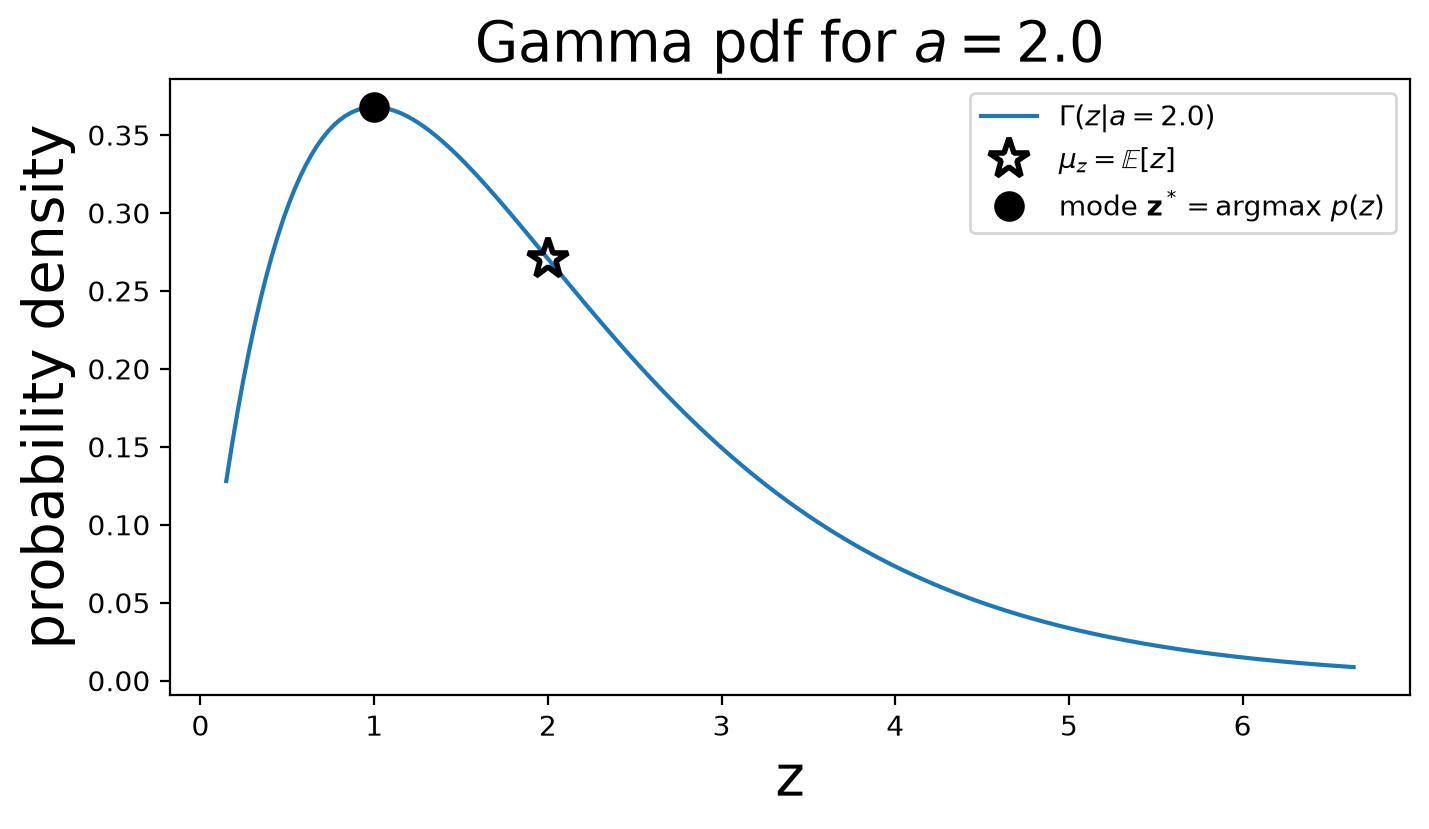

In [6]:
# Code to generate this Gamma distribution hidden during presentation (it's shown as notes)

print('The mean is ',mu_z) # print the mean calculated for this gamma pdf
print('The mode is approximately ',mode_z) # print the mode
fig_gamma_pdf # show figure of this gamma pdf

In [7]:
# @title Figure code: the car stopping distance plot (governing model and true 95% interval)
# This cell is hidden during presentation. It's just to define a function to plot the governing model of
# the car stopping distance problem. Defining a function that creates a plot allows to repeatedly run
# this function on cells used in this notebook.
def car_fig(ax):
    x = np.linspace(3, 83, 1000)
    mu_z = 1.5; sigma_z = 0.5;  # parameters of the "true" p(z)
    mu_y = mu_z*x + 0.1*(x**2) # Recall: E[z*x+0.1*x^2] = x*E[z]+0.1*x^2  (x is not an rv)
    sigma_y = np.sqrt( sigma_z**2*x**2 ) # Recall: V[z*x+0.1*x^2] = x^2*V[z] = sigma_z^2*x^2  (x is not an rv)
    ax.set_xlabel("x (m/s)", fontsize=20) # create x-axis label with font size 20
    ax.set_ylabel("y (m)", fontsize=20) # create y-axis label with font size 20
    ax.set_title("Car stopping distance problem", fontsize=20); # create title with font size 20
    ax.plot(x, mu_y, 'k:', label=r"Governing model $\mu_y$")
    ax.fill_between(x, mu_y - 1.9600 * sigma_y,
                    mu_y + 1.9600 * sigma_y,
                    color='k', alpha=0.2,
                    label=r'95% interval of $p(y)$ ($\mu_y \pm 1.96\sigma_y$)') # central 95% interval of the true p(y)
    ax.legend(fontsize=15)

## Consider an even simpler car distance problem

<img src="../figures/reaction-braking-stopping.svg" title="Car stopping distance" width="25%" align="right">
<br></br>
For now, let's focus on the case where every driver is going at the same velocity $x=75$ m/s.

Then, the governing model is even simpler:

${\color{red}y} = {\color{blue}z}\cdot 75 + 0.1\cdot 75^2 = 75 {\color{blue}z} + 562.5$

- ${\color{red}y}$ is the **output**: the car stopping distance (in meters)
- ${\color{blue}z}$ is a hidden variable: an <a title="random variable">rv</a> representing the driver's reaction time (in seconds)

where $z \sim \mathcal{N}(\mu_z=1.5,\sigma_z^2=0.5^2)$

In [8]:
# Let's make different observations
from scipy.stats import norm # import the normal dist, as we learned before!
# Define our car stopping distance function
def samples_y(N_samples,x): # observations/measurements/samples of car stop. dist. prob.
    mu_z = 1.5; sigma_z = 0.5;  # parameters of the "true" p(z)
    samples_z = norm.rvs(mu_z, sigma_z, size=N_samples) # randomly draw samples from the normal dist.
    samples_y = samples_z*x + 0.1*x**2 # compute the stopping distance for samples of z
    return samples_y # return samples of y

print("Stopping distance for x=75 m/s is:",samples_y(N_samples=1,x=75)) # drawing random samples of y

Stopping distance for x=75 m/s is: [651.16061242]


### Let's estimate the 95% interval of $p(y)$ for $x=75$ m/s

- Let's estimate, from samples of different sizes, the interval where 95% of the stopping distances fall (error bar: empirical mean $\pm 1.96\times$ empirical standard deviation).

- We will also overlay this with the true interval obtained from the governing model (grey band).

Empirical mean[y] is 717.6581700749354 (real mean[y]=675)
Empirical std[y] is 33.038727257845856 (real std[y]=37.5)


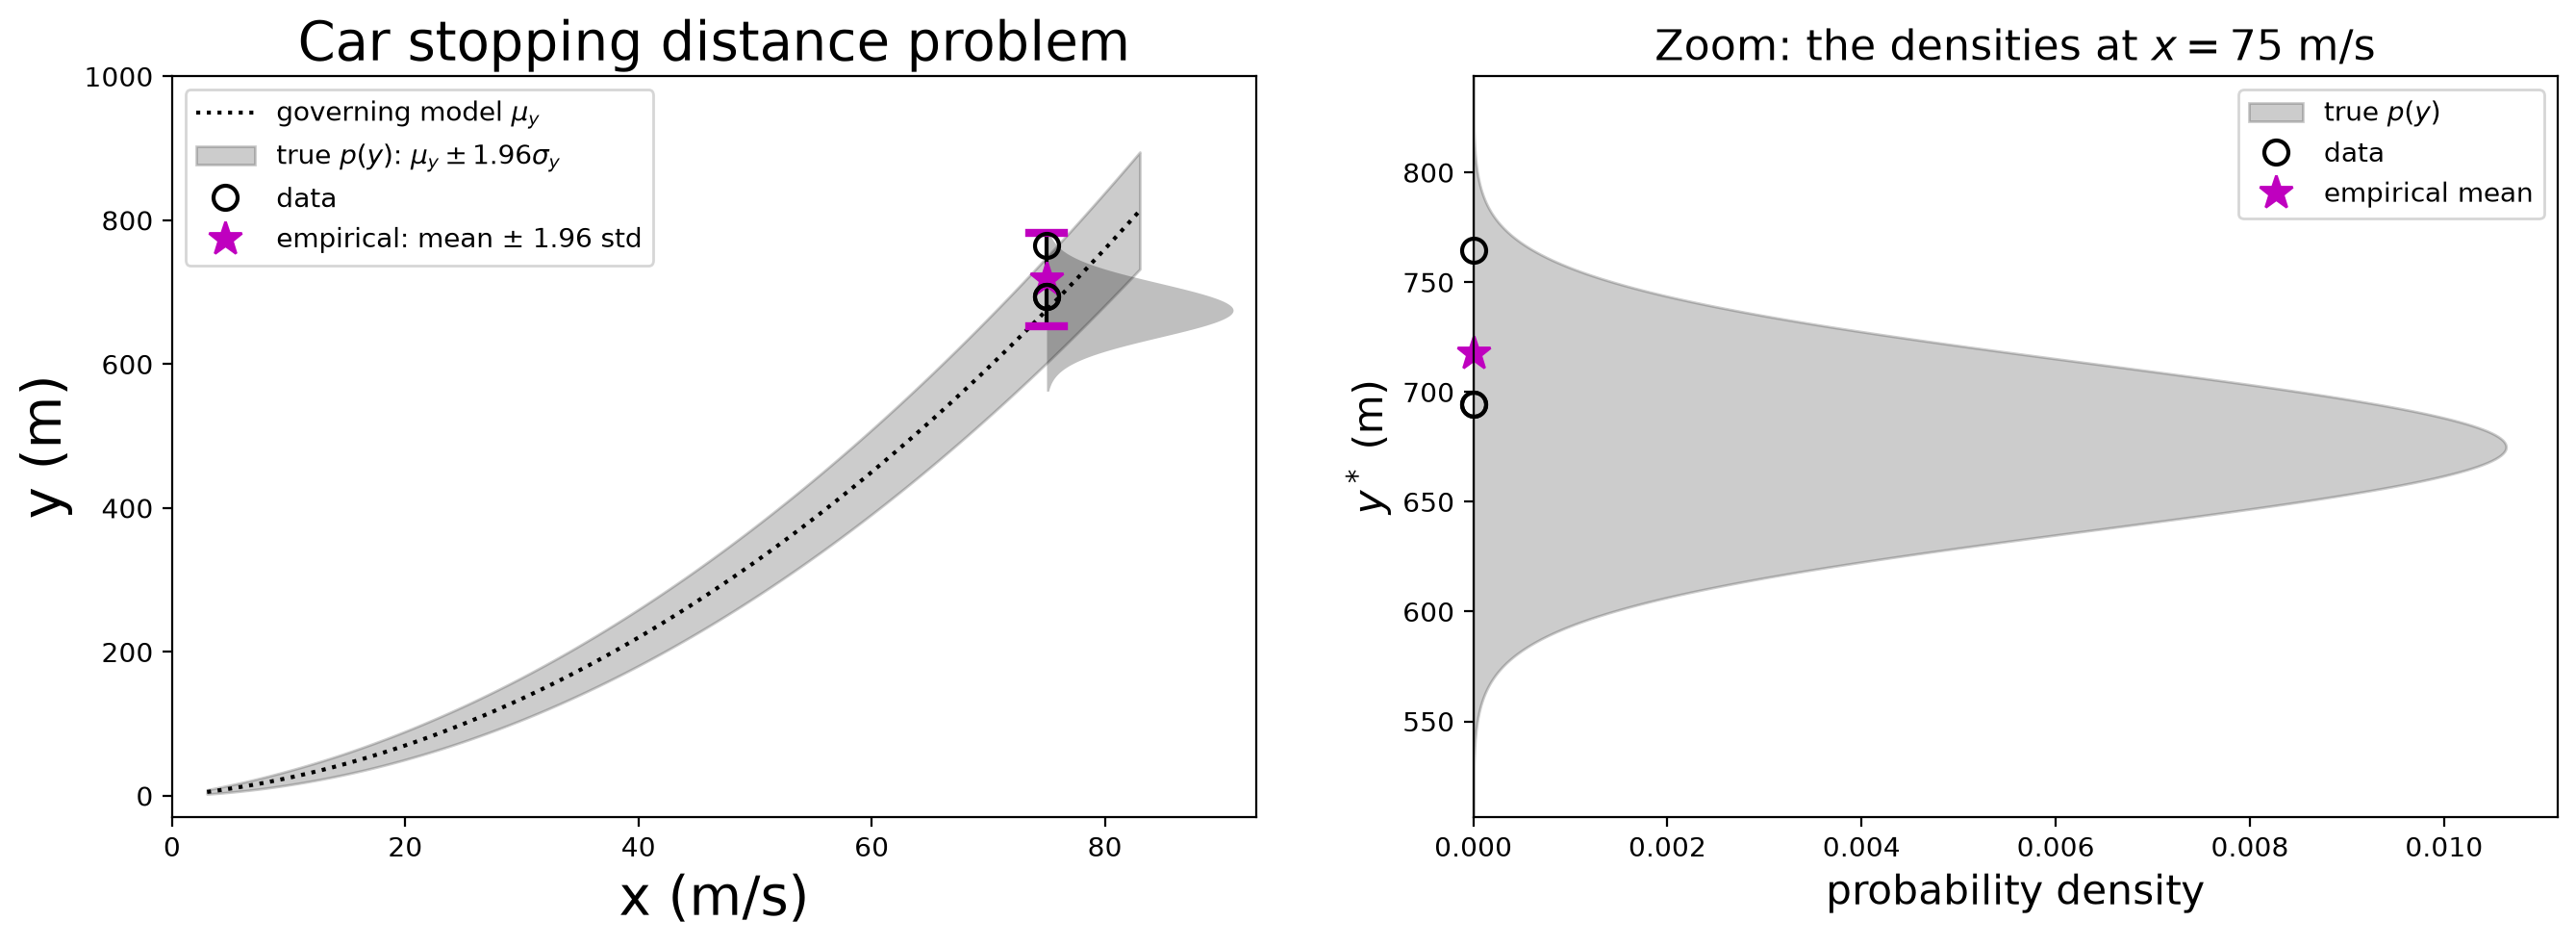

In [9]:
N_samples = 3 # CHANGE THIS NUMBER AND RE-RUN THE CELL
x = 75; empirical_y = samples_y(N_samples, x); # Empirical measurements of N_samples at x=75
empirical_mu_y = np.mean(empirical_y); empirical_sigma_y = np.std(empirical_y); # empirical mean and std
fig_car_new, ax_car_new = plt.subplots(1,2) # two plots: the overview, and a zoom at x
plot_PPDs(ax_car_new, x, empirical_y, []) # a function I created: the data at x, on top of the governing model
print("Empirical mean[y] is",empirical_mu_y, "(real mean[y]=675)")
print("Empirical std[y] is",empirical_sigma_y,"(real std[y]=37.5)")
fig_car_new.set_size_inches(16, 5) # scale figure to be wider (since there are 2 subplots)

### Confidence interval vs credible interval

In frequentist statistics, we use the variability induced by the sampling distribution as a way to
estimate uncertainty of a parameter estimate (e.g. mean and standard deviation). More precisely, we define a 100(1 − α)% confidence interval (CI) for a parameter derived from a dataset $\mathcal{D}$.

It is common to set $\alpha = 0.05$, which yields a 95% CI. **This means that, if we repeatedly sample
data, and compute $CI(\mathcal{D})$ for each such dataset, then about 95% of such intervals will contain the true
parameter (e.g. the true mean or the true standard deviation).**

Note, however, that this **DOES NOT** mean that for any particular dataset that the parameter belongs to the CI
with 95% probability! This is what a Bayesian credible interval computes (see book Sections 4.6.6, 4.7.4 and 4.7.5), not what a frequentist confidence interval computes.

#### ...and the error bar above is neither of them!

The magenta error bar (empirical mean $\pm 1.96\times$ empirical standard deviation) and the grey band ($\mu_y \pm 1.96\sigma_y$) are **not** confidence intervals, and they are **not** credible intervals either. They are the interval where 95% of the stopping distances $y$ fall, i.e. a property of $p(y)$ itself.

* Increase $N$ in the cell above: the error bar does **not** shrink. It converges to the grey band, $\pm 1.96\times 37.5 \approx \pm 73.5$ m.
* A 95% confidence interval for the **mean** of $y$ would instead be approximately $\pm 1.96\,\sigma_y/\sqrt{N}$, which shrinks to zero as $N$ grows (about $\pm 4$ m for $N=300$).
* The magenta bar is closest to a 95% **prediction interval**, i.e. an interval for a *new* observation $y^*$: for Gaussian data with known $\sigma_y$ it is $\bar{y} \pm 1.96\,\sigma_y\sqrt{1+1/N}$. That is why it converges to $\pm 1.96\,\sigma_y$ instead of vanishing: no amount of data makes the next driver predictable.

| Interval | What is uncertain | Shrinks to zero as $N\rightarrow\infty$? |
|---|---|---|
| Central 95% interval of a known $p(y)$ (grey band) | nothing: $p(y)$ is known | no, it is fixed |
| Empirical 95% interval (magenta bar) | nothing: plug-in estimate from data | no, converges to the grey band |
| Confidence interval (frequentist) | a parameter, e.g. the mean of $y$ | yes |
| Prediction interval (frequentist) | a new observation $y^*$ | no, stops at the noise |
| Credible interval (Bayesian) | a hidden rv, e.g. $z$ | yes (for our models) |
| Posterior predictive interval (Bayesian) | a new observation $y^*$ | no, stops at the noise |

We will meet the Bayesian ones from Lecture 6 onwards.

Mixing up these intervals is a very common mistake, even among experienced practitioners.

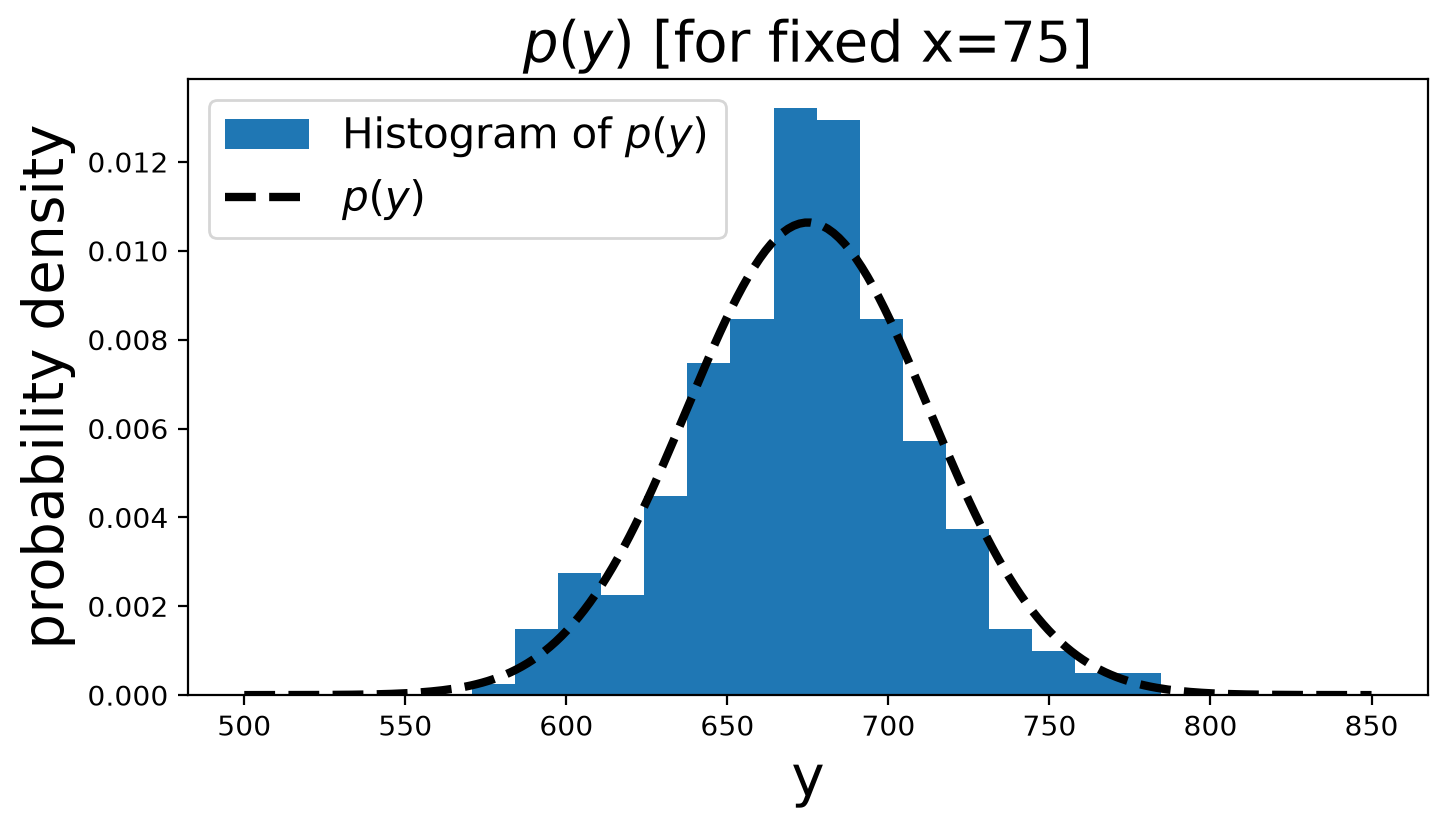

In [10]:
fig_hist, ax_hist_y = plt.subplots()
# Plot the histogram obtained by sampling p(y) with data
empirical_y = samples_y(N_samples=300,x=75) # CHANGE NUMBER OF SAMPLES AND RE-RUN CELL
ax_hist_y.hist(empirical_y, bins='auto', 
               density=True, label='Histogram of $p(y)$')  
ax_hist_y.set_title("$p(y)$ [for fixed x=75]", fontsize=20)

# Plot the actual p(y) pdf:
yrange = np.linspace(500, 850, 200) # to show the real Gaussian distribution
ax_hist_y.plot(yrange, norm.pdf(yrange, 675, 37.5), 'k--', linewidth = 3, label='$p(y)$')
ax_hist_y.set_xlabel("y", fontsize=20)
ax_hist_y.set_ylabel("probability density", fontsize=20)
ax_hist_y.legend(fontsize=15, loc='upper left');

## Conclusions about $y$ and $z$

* We conclude that $y$ is also an <a title="random variable">rv</a> because $z$ is an <a title="random variable">rv</a>.

* In this case, we empirically found that $p(y)$ is also a Gaussian distribution, just like $z$ but with different parameters. This makes sense because $y$ is just linearly dependent on $z$.

* In **Homework 2** you will calculate the expected value (mean) and variance of $y$.

These observations lead to the conclusion:

$$
p(y) = \mathcal{N}(\mu_{y}=675,\sigma_{y}^2=37.5^2)
$$

with $p(z) = \mathcal{N}(\mu_z=1.5,\sigma_z^2=0.5^2)$ and for $x=75$.

### Homework 2 (Exercise 2)
<a id='exercise2_cell'></a>
<img src="../figures/reaction-braking-stopping.svg" title="Car stopping distance" width="25%" align="right">

Our famous car stopping distance problem:

${\color{red}y} = {\color{blue}z} x + 0.1 x^2$

where $z \sim \mathcal{N}(\mu_z=1.5,\sigma_z^2=0.5^2)$

Derive the expected value and variance for the governing model for the car stopping distance problem:

$\mathbb{E}[y]=?$

$\mathbb{V}[y]=?$



## Transformation of random variables

This empirical conclusion can be reached analytically from the **change of variables formula**.

This formula says that if $y=f(z)$ and if this function is invertible, i.e. $z=f^{-1}(y)=g(y)$, then:

$$
p_y(y) = p_z\left( g(y) \right) \left| \frac{d}{dy}g(y)\right|
$$

where $g(y) = f^{-1}(y)$.

### Homework 2 (Exercise 3)

Use the change of variables formula to demonstrate that $p(y)$ is a Gaussian distribution with the expected value and variance determined previously. In other words, that $p(y)=\mathcal{N}(y|\mu_{y}=x\mu_z+0.1x^2, \sigma_y^2 = \sigma_z^2 x^2)$ when $y=zx + 0.1x^2$.

## Transformation of random variables (multivariate)

For more information about transformation of random variables read Section 2.8 of the book.

The multivariate change of variables formula is:

$$
p_y(\mathbf{y}) = p_z\left( \mathbf{g}(\mathbf{y}) \right) \left| \text{det}\left[\mathbf{J}_g(\mathbf{y})\right]\right|
$$

where $\mathbf{J}_g(\mathbf{y})=\frac{d\mathbf{g}(\mathbf{y})}{d\mathbf{y}^T}$ is the jacobian of $\mathbf{g}$ and $\text{det}\left[\mathbf{J}_g(\mathbf{y})\right]$ is the absolute value of the determinant of $\mathbf{J}_g$ evaluated at $\mathbf{y}$.

## Introducing joint probability density of $y$ and $z$

Just like in Lecture 1 where we talked about **joint probability** of two events, $\text{Pr}(A \wedge B)= \text{Pr}(A, B)$, the **joint probability density** is:

$$
p(y \wedge z)= p(y, z)
$$

- But how do we **calculate** $p(y,z)$?

**If** the two rv's were independent, then it would be: $p(y,z)=p(y)p(z)$

**But...** We know that $y$ is dependent on $z$... So now what do we do?

## What is the joint probability density of $y$ and $z$?

As we saw in Lecture 1, 

$$
p(y, z) = p(y|z)p(z) = p(z|y)p(y) = p(z, y)
$$

Here, we already know $p(y)$ and $p(z)$.

* But what is the **conditional pdf** $p(y|z)$?

Remember that for now we are assuming that we know the governing model: $y=z x+0.1x^2$

So, what is the **conditional pdf** $p(y|z)$? <font color='blue'>Tell me what you think!</font>

## The conditional pdf $p(y|z)$ if we know the model... Dirac delta!

$p(y|z)=\delta\left(y-(z x+0.1x^2)\right)$

This is the Dirac delta pdf, assigning zero probability everywhere except when $y=z x+0.1x^2$

#### Note: two properties of the Dirac delta you will need

- **Sifting property:** $\int f(z)\delta(z-a)\,dz = f(a)$. Multiplying by a Dirac delta and integrating just "picks out" the value of $f$ at the point where the delta is centered.

- **Scaling property:** $\delta(az) = \delta(z)/|a|$. Rescaling the argument of the delta rescales its "weight" so that it still integrates to 1.

Both are used in **Homework 2** when you marginalize a deterministic relation $y=g(z)$ (i.e. integrate $p(y,z)=\delta(y-g(z))p(z)$ over $z$) to obtain $p(y)$.

If we want to consider this for a fixed $x$ at 75 m/s:

$p(y|z)=\delta\left(y-(75 z+562.5)\right)$

This was not a trick question, although a lot of people do not think about this answer when first thinking about the problem 😉

* Then, what is the **joint pdf** $p(y,z)$?

## What is the joint probability density of $y$ and $z$?

Since $y$ and $z$ are dependent, the joint pdf $p(y,z)$ is

$$
p(y, z) = \delta\left(y-(75 z+562.5)\right) p(z)
$$

where $p(y|z)=\delta\left(y-(75 z+562.5)\right)$ is the above-mentioned Dirac delta pdf, assigning zero probability everywhere except when $y=75 z+562.5$ for a fixed $x=75$ m/s.

Recall that $p(z) = \mathcal{N}(\mu_z=1.5,\sigma_z^2=0.5^2)$, also for a fixed $x=75$ m/s.

* Note: $p(y,z)$ and $p(y|z)$ are pdf's that depend on *both* $y$ and $z$, but the joint pdf $p(y,z)$ has two rv's while the conditional pdf $p(y|z)$ is conditioned to a value of $z$ (it's like "removing" the stochasticity of $z$).

## Why do we care about joint pdfs?

In general, from a joint pdf $p(y,z)$ we can obtain $p(y)$ and $p(z)$ simply by **integrating out** wrt the other variable. This is called **marginalizing**:

$$
p(y) = \int p(y,z) dz
$$

$$
p(z) = \int p(y,z) dy
$$

Therefore, $p(y)$ and $p(z)$ are also called **marginal distributions** of $p(y,z)$.

### Homework 2 (Exercise 4)

Knowing that $p(y, z) = \delta\left(y-(z x+0.1x^2)\right)  \mathcal{N}(z|\mu_z,\sigma_z^2)$, calculate $p(y)$ and $p(z)$.

## In general, do we know the true conditional distribution $p(y|z)$?

Unfortunately, we usually don't know the true conditional pdf $p(y|z)$ because $z$ is hidden!

(Remember: we are cheating with the *car stopping distance problem* because we already know that $y=zx+0.1x^2$

In general, we don't know the true relationship between $y$ and $z$...

* So, what can we do?

We can **observe** the effect caused by the hidden $z$ in $y$ by taking measurements of $y$.

In other words, within the measurements of $y$ (which we call data $\mathcal{D}_y$) lies the *effect* of the hidden $z$.

* The Bayes' rule provides a way to estimate the distribution of the hidden rv $z$ given data $\mathcal{D}_y$.

### Side note: conditional moments (book Section 2.2.5.4)

On purpose, I skipped talking about conditional moments in Lecture 1...

But now that we talked about conditional pdf's, it's a good time to introduce this.

We can calculate the expected value and variance of an rv that is dependent on another rv with the following two laws.

#### Law of iterated expectations

$$
\mathbb{E}[y] = \mathbb{E}\left[\mathbb{E}[y|z]\right]
$$

#### Law of total variance (or conditional variance formula)

$$
\mathbb{V}[y] = \mathbb{E}\left[\mathbb{V}[y|z]\right]+\mathbb{V}\left[\mathbb{E}[y|z]\right]
$$

## Field guide: what this lecture adds

### Key concepts

**Probability**
- **Joint, marginal and conditional distributions.** Marginalizing a variable means integrating it out.
- **Moments**: the expected value is linear; the variance of a sum of independent variables is the sum of their variances; mean and mode differ for asymmetric distributions.
- **Change of variables**: how a pdf transforms when its variable is transformed.

**Bayesian inference**
- **Credible, confidence and prediction intervals** answer different questions.

The whole [field guide](https://github.com/bessagroup/3dasm_course/blob/main/FIELD_GUIDE.md) collects the key concepts and good practices of every lecture.

### See you next class

Have fun!